# Laboratório visual: circuitos série e contador JK

Este notebook oferece controles e gráficos para respostas transitórias de circuitos **RC, RL e RLC em série** e para a máquina de estados de um contador síncrono JK binário de largura configurável. Os modelos aceitam valores definidos por você; eles não reproduzem páginas ou exemplos de um livro específico.

Instale as dependências com `python -m pip install -r ../requirements-simulacao.txt` e execute as células em ordem. A solução numérica usa SciPy; Matplotlib e ipywidgets exibem resultados interativos. O modelo da chave ideal alterna a fonte entre a tensão configurada e 0 V.

In [1]:
from pathlib import Path
import sys

project_docs = Path.cwd()
if not (project_docs / "circuit_lab.py").exists():
    project_docs = project_docs.parent
if str(project_docs) not in sys.path:
    sys.path.insert(0, str(project_docs))

import html
import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets
from IPython.display import HTML, clear_output, display

from circuit_lab import JKCounter, simulate_series_circuit

plt.style.use("dark_background")
print("Modelos prontos: RC, RL, RLC série e contador JK binário.")

Modelos prontos: RC, RL, RLC série e contador JK binário.


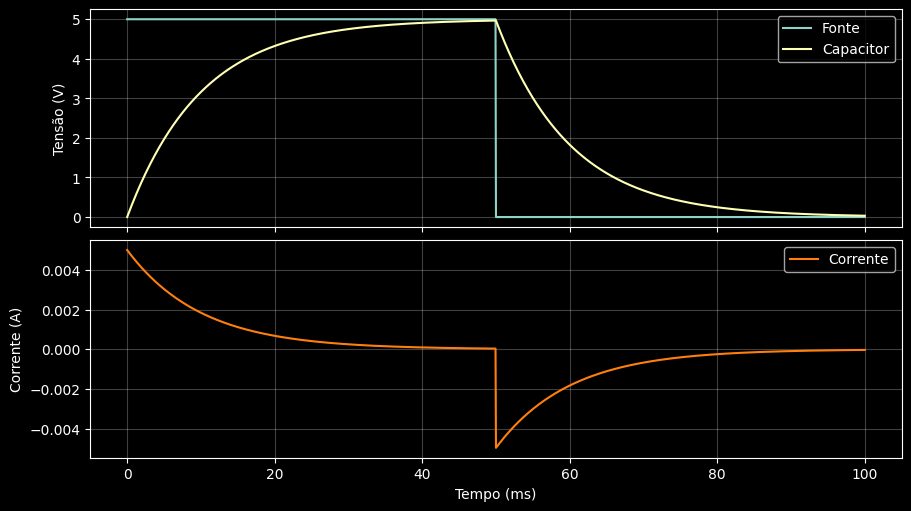

In [2]:
# Primeiro resultado visível, mesmo sem interagir com os controles do notebook.
example = simulate_series_circuit(
    "RC", resistance=1e3, capacitance=1e-5, source_voltage=5,
    duration=0.1, samples=800, switch_events=[(0, True), (0.05, False)],
)
figure, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True, constrained_layout=True)
axes[0].plot(example.time * 1e3, example.source_voltage, label="Fonte")
axes[0].plot(example.time * 1e3, example.capacitor_voltage, label="Capacitor")
axes[0].set_ylabel("Tensão (V)")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(example.time * 1e3, example.current, color="tab:orange", label="Corrente")
axes[1].set_xlabel("Tempo (ms)")
axes[1].set_ylabel("Corrente (A)")
axes[1].legend()
axes[1].grid(alpha=0.25)
display(figure)
plt.close(figure)

## RC, RL e RLC: carga, descarga e resposta transitória

Escolha os valores abaixo. Se **Mostrar descarga** estiver ativo, a chave fecha na metade inicial da simulação e abre em seguida. O estado armazenado no capacitor e/ou indutor é preservado quando a chave abre. As curvas mostram a tensão da fonte, as quedas de tensão nos componentes e a corrente; o terceiro gráfico mostra as energias armazenadas.

In [6]:
circuit_control = widgets.Dropdown(
    options=[("RC série", "RC"), ("RL série", "RL"), ("RLC série", "RLC")],
    value="RC", description="Circuito:",
)
resistance_control = widgets.FloatLogSlider(
    value=1e3, base=10, min=0, max=6, step=0.05,
    description="R (Ω):", readout_format=".3g", continuous_update=False,
)
inductance_control = widgets.FloatLogSlider(
    value=1e-2, base=10, min=-6, max=1, step=0.05,
    description="L (H):", readout_format=".3g", continuous_update=False,
)
capacitance_control = widgets.FloatLogSlider(
    value=1e-5, base=10, min=-9, max=-2, step=0.05,
    description="C (F):", readout_format=".3g", continuous_update=False,
)
source_control = widgets.FloatSlider(
    value=5, min=0, max=24, step=0.5,
    description="Fonte (V):", continuous_update=False,
)
duration_control = widgets.FloatLogSlider(
    value=0.5, base=10, min=-4, max=2, step=0.05,
    description="Duração (s):", readout_format=".3g", continuous_update=False,
)
discharge_control = widgets.Checkbox(
    value=True, description="Mostrar carga e descarga", indent=False,
)
samples_control = widgets.IntSlider(
    value=1200, min=300, max=3000, step=100,
    description="Amostras:", continuous_update=False,
)
circuit_output = widgets.Output()

def plot_circuit(circuit, resistance, inductance, capacitance, source, duration, show_discharge, samples):
    events = [(0.0, True)]
    if show_discharge:
        events.append((duration / 2, False))
    result = simulate_series_circuit(
        circuit,
        resistance=resistance,
        inductance=inductance,
        capacitance=capacitance,
        source_voltage=source,
        duration=duration,
        samples=samples,
        switch_events=events,
    )
    time_ms = result.time * 1e3
    with circuit_output:
        clear_output(wait=True)
        figure, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, constrained_layout=True)
        axes[0].plot(time_ms, result.source_voltage, label="Fonte", linewidth=1.8)
        axes[0].plot(time_ms, result.resistor_voltage, label="Resistor", linewidth=1.6)
        if circuit in ("RC", "RLC"):
            axes[0].plot(time_ms, result.capacitor_voltage, label="Capacitor", linewidth=1.6)
        if circuit in ("RL", "RLC"):
            axes[0].plot(time_ms, result.inductor_voltage, label="Indutor", linewidth=1.6)
        axes[0].set_ylabel("Tensão (V)")
        axes[0].legend(ncol=4, loc="best")
        axes[0].grid(alpha=0.2)
        axes[1].plot(time_ms, result.current, color="tab:orange", label="Corrente da malha")
        axes[1].set_ylabel("Corrente (A)")
        axes[1].legend(loc="best")
        axes[1].grid(alpha=0.2)
        if circuit in ("RC", "RLC"):
            axes[2].plot(time_ms, result.capacitor_energy, label="Energia no capacitor")
        if circuit in ("RL", "RLC"):
            axes[2].plot(time_ms, result.inductor_energy, label="Energia no indutor")
        axes[2].set_xlabel("Tempo (ms)")
        axes[2].set_ylabel("Energia (J)")
        axes[2].legend(loc="best")
        axes[2].grid(alpha=0.2)
        display(figure)
        plt.close(figure)

circuit_controls = widgets.VBox([
    circuit_control,
    widgets.HBox([resistance_control, inductance_control, capacitance_control]),
    widgets.HBox([source_control, duration_control]),
    widgets.HBox([discharge_control, samples_control]),
])
circuit_plot = widgets.interactive_output(
    plot_circuit,
    {
        "circuit": circuit_control,
        "resistance": resistance_control,
        "inductance": inductance_control,
        "capacitance": capacitance_control,
        "source": source_control,
        "duration": duration_control,
        "show_discharge": discharge_control,
        "samples": samples_control,
    },
)
display(circuit_controls, circuit_output, circuit_plot)

Output()

Output()

### Como interpretar os modelos

- **RC:** a variável de estado é a tensão do capacitor; `i = (v_fonte - v_C) / R` e `dv_C/dt = i/C`.
- **RL:** a variável de estado é a corrente do indutor; `v_L = v_fonte - R i` e `di/dt = v_L/L`.
- **RLC série:** as variáveis de estado são a corrente da malha e a tensão do capacitor; a integração respeita `v_fonte = v_R + v_L + v_C`.

São modelos concentrados ideais em regime transitório, com condições iniciais nulas e fonte ideal com chave. Para estudar um exercício, ajuste os parâmetros, a duração e o chaveamento aos dados do enunciado.

## Máquina de estados do contador síncrono JK

Defina qualquer largura positiva e escolha a direção. O modelo percorre os `2ⁿ` estados, volta ao início no overflow/underflow e fornece a tabela de excitação JK necessária para cada transição. `X` significa condição indiferente na tabela de excitação do flip-flop.

In [4]:
bits_control = widgets.IntSlider(
    value=3, min=1, max=8, step=1, description="Bits:", continuous_update=False,
)
direction_control = widgets.Dropdown(
    options=[("Crescente", "UP"), ("Decrescente", "DOWN")],
    value="UP", description="Direção:",
)
initial_state_control = widgets.IntSlider(
    value=0, min=0, max=7, step=1, description="Estado inicial:", continuous_update=False,
)
counter_output = widgets.Output()

def update_state_range(change):
    maximum = (1 << change["new"]) - 1
    initial_state_control.max = maximum
    if initial_state_control.value > maximum:
        initial_state_control.value = maximum

bits_control.observe(update_state_range, names="value")

def show_counter(bit_count, direction, initial_state):
    counter = JKCounter(bit_count, direction, initial_state)
    rows = counter.transition_table()
    visible_rows = rows if len(rows) <= 64 else rows[:32] + rows[-32:]
    sequence = [counter.bits]
    for _ in range(counter.modulus):
        sequence.append(counter.clock())
    with counter_output:
        clear_output(wait=True)
        figure, axis = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
        axis.step(range(len(sequence)), [int(value, 2) for value in sequence], where="post")
        axis.set_title(f"Contador {direction.lower()} de {bit_count} bits · módulo {counter.modulus}")
        axis.set_xlabel("Pulso de clock")
        axis.set_ylabel("Estado decimal")
        axis.set_yticks(range(counter.modulus))
        axis.grid(alpha=0.25)
        display(figure)
        plt.close(figure)
        if len(rows) > len(visible_rows):
            print(f"Exibindo 64 de {len(rows)} estados; counter.transition_table() retorna a tabela completa.")
        headers = ("Estado atual", "J (MSB→LSB)", "K (MSB→LSB)", "Próximo estado", "Decimal seguinte")
        header_html = "".join(f"<th>{html.escape(label)}</th>" for label in headers)
        body_html = "".join(
            "<tr>" + "".join(
                f"<td>{html.escape(str(row[key]))}</td>"
                for key in ("state", "J", "K", "next_state", "decimal")
            ) + "</tr>"
            for row in visible_rows
        )
        display(HTML(
            "<div style='max-height:420px;overflow:auto'><table style='border-collapse:collapse' border='1' cellpadding='5'>"
            f"<thead><tr>{header_html}</tr></thead><tbody>{body_html}</tbody></table></div>"
        ))

counter_controls = widgets.HBox([bits_control, direction_control, initial_state_control])
counter_view = widgets.interactive_output(
    show_counter,
    {"bit_count": bits_control, "direction": direction_control, "initial_state": initial_state_control},
)
display(counter_controls, counter_output, counter_view)

Output()

Output()

### Tabela-verdade característica do flip-flop JK

Esta tabela é independente da largura do contador. A transição do contador é construída escolhendo `J` e `K` para que o flip-flop alcance o próximo bit; a tabela completa dessa máquina está no controle acima.

In [5]:
jk_truth = """
<table border='1' cellpadding='7' style='border-collapse:collapse'>
<thead><tr><th>J</th><th>K</th><th>Q(t)</th><th>Q(t+1)</th><th>Operação</th></tr></thead>
<tbody>
<tr><td>0</td><td>0</td><td>0</td><td>0</td><td>Manter</td></tr>
<tr><td>0</td><td>0</td><td>1</td><td>1</td><td>Manter</td></tr>
<tr><td>0</td><td>1</td><td>0</td><td>0</td><td>Reset</td></tr>
<tr><td>0</td><td>1</td><td>1</td><td>0</td><td>Reset</td></tr>
<tr><td>1</td><td>0</td><td>0</td><td>1</td><td>Set</td></tr>
<tr><td>1</td><td>0</td><td>1</td><td>1</td><td>Set</td></tr>
<tr><td>1</td><td>1</td><td>0</td><td>1</td><td>Alternar</td></tr>
<tr><td>1</td><td>1</td><td>1</td><td>0</td><td>Alternar</td></tr>
</tbody></table>
"""
display(HTML(jk_truth))

J,K,Q(t),Q(t+1),Operação
0,0,0,0,Manter
0,0,1,1,Manter
0,1,0,0,Reset
0,1,1,0,Reset
1,0,0,1,Set
1,0,1,1,Set
1,1,0,1,Alternar
1,1,1,0,Alternar
